In [233]:
import pandas as pd
import numpy as np
from eval_plot_utils import parse_yml_pred,output_evaluation_outputs

In [234]:
test_dat = pd.read_pickle('${KSI_REPO_ROOT}/kinase_ml/data/kinbertv2_pred/kinbertv2_DB_Test.pkl')

In [235]:
test_dat = test_dat.loc[:,['kinase','substrate','kinase_seq','substrate_seq','p_ind','p_aa','source','label']]

In [236]:
test_dat = test_dat.loc[test_dat['source']=='ms',:]

In [237]:
kinbert_long_pred = parse_yml_pred('./eval_outputs/exp_tape_bertbase_sep_v2_long__linkphinder__53ceb023016e.pkl').drop_duplicates()

In [238]:
kinbert_short_pred = parse_yml_pred('./eval_outputs/exp_tape_bertbase_sep_v2__linkphinder__1b97f9a11dd9.pkl').drop_duplicates()

In [239]:
phosformer_pred = pd.read_csv('./eval_outputs/phosformer/pairs_aug_linkphinder.csv').iloc[:,1:]

In [240]:
kolossus_pred = pd.read_csv('./eval_outputs/kolossus/pairs_aug_linkphinder.csv').iloc[:,1:]

In [241]:
pairs_aug_linkphinder = pd.read_csv('../../data/pairs_aug_linkphinder.csv').iloc[:,1:]

In [242]:
pairs_aug_linkphinder = pairs_aug_linkphinder.loc[:,['kinase','substrate','kinase_seq','substrate_seq','kinase_domain_seq','substrate_seq_15aa','p_ind','p_aa','label']]

In [243]:
kolossus_pred.columns = ['kinase_seq','substrate_seq_15aa','kolossus_pred']
pairs_aug_linkphinder = pd.merge(pairs_aug_linkphinder,kolossus_pred,on = ['kinase_seq','substrate_seq_15aa'])

In [244]:
phosformer_pred = phosformer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosformer_pred.columns = ['kinase_domain_seq','substrate_seq_15aa','phosformer_pred']
pairs_aug_linkphinder = pd.merge(pairs_aug_linkphinder,phosformer_pred,on = ['kinase_domain_seq','substrate_seq_15aa'])

In [245]:
kinbert_short_pred.columns = ['kinase_domain_seq','substrate_seq_15aa','kinbert_pred']

In [246]:
pairs_aug_linkphinder = pd.merge(pairs_aug_linkphinder,kinbert_short_pred,on = ['kinase_domain_seq','substrate_seq_15aa'])

In [247]:
# kinbert_long_pred

In [248]:
pairs_aug_linkphinder.to_csv('260504_linkphinder_benchmark_full.csv')

In [249]:
pairs_aug_linkphinder.columns

Index(['kinase', 'substrate', 'kinase_seq', 'substrate_seq',
       'kinase_domain_seq', 'substrate_seq_15aa', 'p_ind', 'p_aa', 'label',
       'kolossus_pred', 'phosformer_pred', 'kinbert_pred'],
      dtype='str')

In [250]:
pairs_aug_linkphinder['kolossus_pred'] = (pairs_aug_linkphinder['kolossus_pred']>0.7)
pairs_aug_linkphinder['phosformer_pred'] = (pairs_aug_linkphinder['phosformer_pred']>0.7)
pairs_aug_linkphinder['kinbert_pred'] = (pairs_aug_linkphinder['kinbert_pred']>0.7)

In [251]:
test_pred_ks = pairs_aug_linkphinder.groupby(["kinase","substrate"]).sum().reset_index().loc[:,["kinase","substrate",'label','kolossus_pred', 'phosformer_pred', 'kinbert_pred']]
test_pred_ks["kolossus_pred"] = (test_pred_ks["kolossus_pred"]>0)
test_pred_ks["phosformer_pred"] = (test_pred_ks["phosformer_pred"]>0)
test_pred_ks["kinbert_pred"] = (test_pred_ks["kinbert_pred"]>0)
test_pred_ks["y_true"] = (test_pred_ks["label"]>0)


In [252]:
ms_linkphinder = pd.read_pickle("${KSI_REPO_ROOT}/kinase_ml/data//labeled_data/ms_linkphinder.pkl")

In [253]:
ms_linkphinder["subtrate_in_linkphinder"] = True
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="Noâ\x88\x97","subtrate_in_linkphinder"] = False
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="Yesâ\x88\x97","subtrate_in_linkphinder"] = False
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="Noâ\x88\x97","linkphinder"] = 'No'
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="Yesâ\x88\x97","linkphinder"] = 'Yes'

In [254]:
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="No","linkphinder"] = False
ms_linkphinder.loc[ms_linkphinder["linkphinder"]=="Yes","linkphinder"] = True

In [255]:
ms_linkphinder.to_csv('260504_linkphinder_benchmark_from_linkphinder.csv')

In [256]:
ms_comparison_df = pd.merge(ms_linkphinder,test_pred_ks,on = ["kinase","substrate"])

In [257]:
ms_comparison_df["linkphinder"] = ms_comparison_df["linkphinder"].astype('bool')

In [258]:
ms_comparison_df["y_true"] = True

In [259]:
ms_comparison_df = ms_comparison_df.groupby("kinase").sum().reset_index()

In [260]:
ms_comparison_df.loc[len(ms_comparison_df)] = ["total"] + ms_comparison_df.iloc[:,1:].values.sum(axis = 0).tolist()

In [261]:
# ms_comparison_df["kinbert_acc"] = ms_comparison_df["kinbert_bool"]/ms_comparison_df["y_true"]
# ms_comparison_df["linkphinder_acc"] = ms_comparison_df["linkphinder"]/ms_comparison_df["y_true"]
# ms_comparison_df["phosformer_acc"] = ms_comparison_df["phosformer_bool"]/ms_comparison_df["y_true"]
# ms_comparison_df["kolossus_acc"] = ms_comparison_df["kolossus_bool"]/ms_comparison_df["y_true"]

ms_comparison_df["kinbert_acc"] = ms_comparison_df["kinbert_pred"]/ms_comparison_df["y_true"]
ms_comparison_df["linkphinder_acc"] = ms_comparison_df["linkphinder"]/ms_comparison_df["y_true"]
ms_comparison_df["phosformer_acc"] = ms_comparison_df["phosformer_pred"]/ms_comparison_df["y_true"]
ms_comparison_df["kolossus_acc"] = ms_comparison_df["kolossus_pred"]/ms_comparison_df["y_true"]

In [262]:
# ms_comparison_df.columns = ['kinase', 'n_linkphinder', 'seen_in_linkphinder', 'n_tape_pred','n_ksi', 'tape_acc', 'linkphinder_acc']

In [263]:
ms_comparison_stats = ms_comparison_df.groupby("kinase").sum().reset_index()

In [264]:
ms_comparison_stats.loc[:,['kinase','linkphinder','kolossus_pred','phosformer_pred','kinbert_pred','y_true','kinbert_acc','linkphinder_acc','phosformer_acc','kolossus_acc']]

,kinase,linkphinder,kolossus_pred,phosformer_pred,kinbert_pred,y_true,kinbert_acc,linkphinder_acc,phosformer_acc,kolossus_acc
0,O95835,6,76,21,147,160,0.918750,0.037500,0.131250,0.475000
1,P17612,4,14,2,18,23,0.782609,0.173913,0.086957,0.608696
2,Q13188,4,114,5,117,130,0.900000,0.030769,0.038462,0.876923
3,total,14,204,28,282,313,0.900958,0.044728,0.089457,0.651757


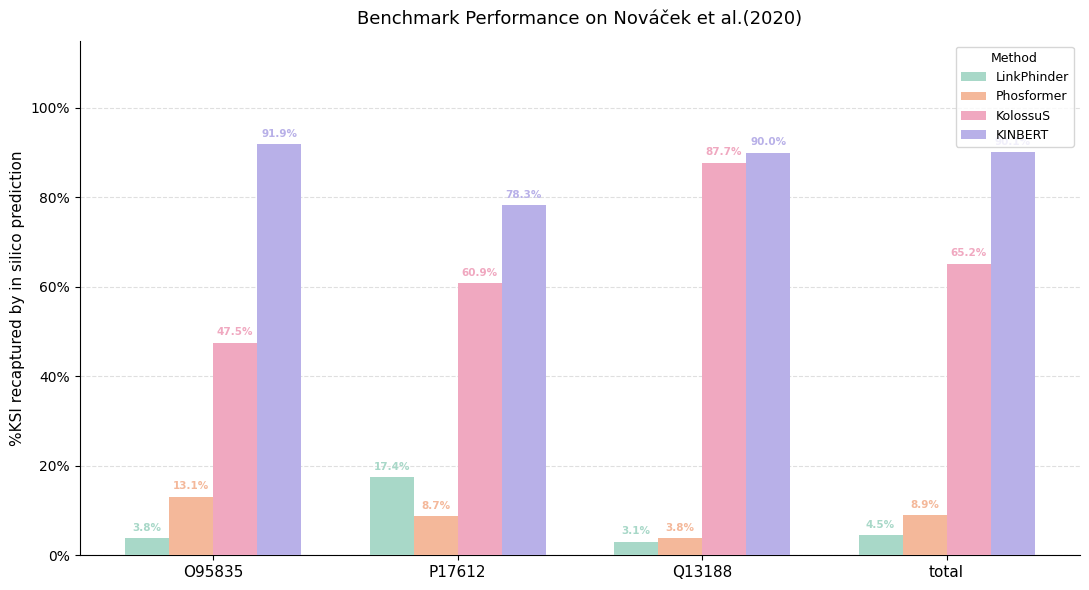

In [269]:
import matplotlib.pyplot as plt
import numpy as np

data = {
    'O95835': {'kinbert': 0.918750, 'linkphinder': 0.037500, 'phosformer': 0.131250, 'kolossus': 0.475000},
    'P17612': {'kinbert': 0.782609, 'linkphinder': 0.173913, 'phosformer': 0.086957, 'kolossus': 0.608696},
    'Q13188': {'kinbert': 0.900000, 'linkphinder': 0.030769, 'phosformer': 0.038462, 'kolossus': 0.876923},
    'total':  {'kinbert': 0.900958, 'linkphinder': 0.044728, 'phosformer': 0.089457, 'kolossus': 0.651757},
}

kinases = list(data.keys())

methods = ['linkphinder', 'phosformer', 'kolossus', 'kinbert']
labels  = ['LinkPhinder', 'Phosformer', 'KolossuS', 'KINBERT']
colors  = ['#A8D8C8', '#F4B89A', '#F0A8C0', '#B8B0E8']
x = np.arange(len(kinases))
width = 0.18
n = len(methods)
offsets = np.linspace(-(n-1)/2, (n-1)/2, n) * width

fig, ax = plt.subplots(figsize=(11, 6))

for i, (method, label, color) in enumerate(zip(methods, labels, colors)):
    vals = [data[k][method] for k in kinases]
    bars = ax.bar(x + offsets[i], vals, width, label=label, color=color, zorder=3)
    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.012,
            f'{val*100:.1f}%',
            ha='center', va='bottom',
            fontsize=7.5, color=color, fontweight='bold'
        )

ax.set_xticks(x)
ax.set_xticklabels(kinases, fontsize=11)
ax.set_ylabel('%KSI recaptured by in silico prediction', fontsize=11)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
ax.legend(title='Method', fontsize=9, title_fontsize=9, loc='upper right')
ax.set_title('Benchmark Performance on Nováček et al.(2020)', fontsize=13, pad=12)
ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()